In [26]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc

dane = pd.read_csv("bank.csv")
X = pd.get_dummies(dane.drop('deposit', axis=1), drop_first=True)
y = dane['deposit'].map({'yes': 1, 'no': 0})

X_temp,X_test,y_temp,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train,X_val,y_train,y_val = train_test_split(X_temp,y_temp,test_size=0.25,random_state=42)

model = LogisticRegression(max_iter=5000)
model.fit(X_train,y_train)


y_test_prob = model.predict_proba(X_test)[:,1]
threshold_1st = [0.1,0.25,0.5,0.75,0.9]


for threshold in threshold_1st:
    y_pred_tresh = (y_test_prob >=threshold).astype(int)
    
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred_tresh).ravel()
    
    accuracy = (tp+tn)/(tp+tn+fp+fn)
    
    tpr = tp/(tp+fn) if (tp+fn) > 0 else 0
    fpr = fp/(fp+tn) if (fp+tn) > 0 else 0
    print(f"Próg {threshold:<4} -> TP: {tp:<4} | FP: {fp:<4} | FN: {fn:<4} | TN: {tn:<4} || Dokładność: {accuracy:.2f} | TPR: {tpr:.2f} | FPR: {fpr:.2f}")
    

    
    
    

Próg 0.1  -> TP: 1058 | FP: 753  | FN: 9    | TN: 413  || Dokładność: 0.66 | TPR: 0.99 | FPR: 0.65
Próg 0.25 -> TP: 1010 | FP: 373  | FN: 57   | TN: 793  || Dokładność: 0.81 | TPR: 0.95 | FPR: 0.32
Próg 0.5  -> TP: 837  | FP: 188  | FN: 230  | TN: 978  || Dokładność: 0.81 | TPR: 0.78 | FPR: 0.16
Próg 0.75 -> TP: 601  | FP: 82   | FN: 466  | TN: 1084 || Dokładność: 0.75 | TPR: 0.56 | FPR: 0.07
Próg 0.9  -> TP: 385  | FP: 37   | FN: 682  | TN: 1129 || Dokładność: 0.68 | TPR: 0.36 | FPR: 0.03


/home/kuba/Documents/Studia/Sem5/ML/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Wraz ze wzrostem progu spada ilość FP, ale diametralnie rośnie ilosc FALSE NEGATIVES, ponieważ biorać pod uwage wyniki tylko prawie pewnie, pomijamy te, które są prawdziwe ale model ma do nich wiecej wątpliwości, co za tym idzie spada nasz recall, a FPR wynosi prawie 0. Accuracy peakuje przy ok. 0.5 a później też spada,wiec ustawianie niewiadomo jak wysokie progu tez osłabia nasze wyniki.

In [27]:
threshold_2nd = np.arange(0,1.01,0.01)
best_treshold = 0
min_cost = float('inf')


tpr_list = []
fpr_list = []
y_val_prob = model.predict_proba(X_val)[:,1]
for thresh in threshold_2nd:
    y_pred_roc = (y_test_prob >=thresh).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred_roc).ravel()
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    tpr_list.append(tpr)
    fpr_list.append(fpr)
    
df_roc = pd.DataFrame({
    'FPR': fpr_list,
    'TPR': tpr_list,
    'Threshold': threshold_2nd
})
fig = px.line(
    df_roc, 
    x='FPR', 
    y='TPR', 
    hover_data=['Threshold'], # To dodaje próg do dymku po najechaniu
    title='Interaktywna Krzywa ROC na podstawie badanych progów'
)
fig.update_layout(
    xaxis_title='False Positive Rate (FPR)',
    yaxis_title='True Positive Rate (TPR)',
    width=800,
    height=600
)
fig.show()

In [28]:
best_treshold=0
min_cost= float('inf')

y_val_prob = model.predict_proba(X_val)[:,1]
for thresh in threshold_2nd:
    y_pred_prob = (y_val_prob >=thresh).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_val,y_pred_prob).ravel()
    cost = 3*fn + 10*fp
    if(cost < min_cost):
        min_cost = cost
        best_treshold=thresh



y_test_prob = model.predict_proba(X_test)[:,1]
y_test_pred = (y_test_prob >= best_treshold).astype(int)

tn,fp,fn,tp = confusion_matrix(y_test,y_test_pred).ravel()
final_cost = 3*fn + 10*fp

print(f"Optimal threshold: {best_treshold} with cost of: {final_cost} ")

Optimal threshold: 0.6 with cost of: 2280 


In [29]:
wagi_bezwzgledne = np.abs(model.coef_[0])

top2_indeksy = np.argsort(wagi_bezwzgledne)[-2:]
najlepsze_zmienne = X.columns[top2_indeksy]
print(f"Dwa najlepsze predykatory to: {najlepsze_zmienne.tolist()}")

Dwa najlepsze predykatory to: ['month_mar', 'poutcome_success']


/home/kuba/Documents/Studia/Sem5/ML/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


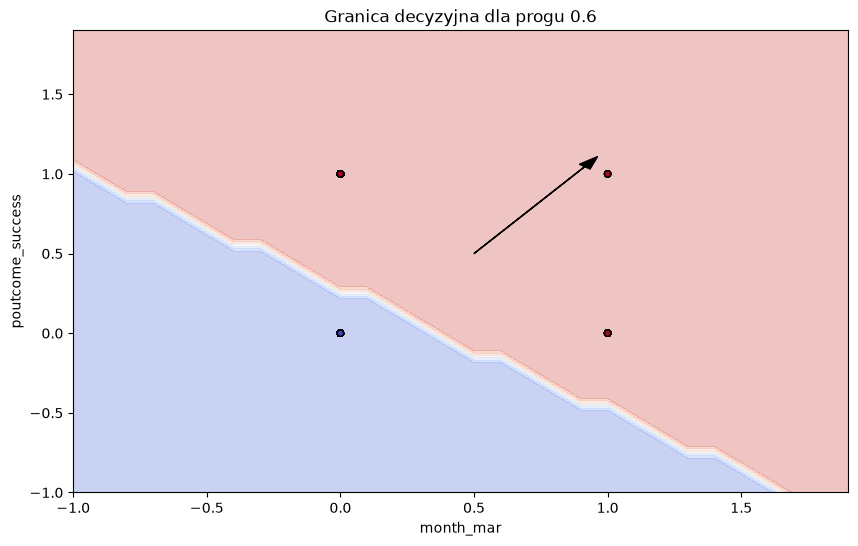

In [30]:
import matplotlib.pyplot as plt
X_train_2d = X_train[najlepsze_zmienne]
X_test_2d = X_test[najlepsze_zmienne]

model_2d = LogisticRegression(max_iter=10000)
model_2d.fit(X_train_2d, y_train)


x_min, x_max = X_train_2d.iloc[:, 0].min() - 1, X_train_2d.iloc[:, 0].max() + 1
y_min, y_max = X_train_2d.iloc[:, 1].min() - 1, X_train_2d.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))


Z_prob = model_2d.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]


Z = (Z_prob >= best_treshold).astype(int)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm') 
plt.scatter(X_test_2d.iloc[:, 0], X_test_2d.iloc[:, 1], c=y_test, cmap='coolwarm', edgecolor='k', s=20)
plt.xlabel(najlepsze_zmienne[0])
plt.ylabel(najlepsze_zmienne[1])
plt.title(f'Granica decyzyjna dla progu {best_treshold}')
w1, w2 = model_2d.coef_[0]


start_x, start_y = 0.5, 0.5
skala = 0.2


plt.arrow(
    start_x, start_y,       
    w1 * skala, w2 * skala,   
    head_width=0.05,        
    head_length=0.08,         
    fc='black', ec='black',   
    zorder=5                  
)


plt.show()